## Opgave

De dataset `Live.csv` bevat informatie over verkopers in Azië die via sociale media hun waren aan de man brengen. Jullie moeten proberen om het status_type als label te reproduceren via clusters. Haal de `status_type` kolom dus van je dataset, en hou deze bij om op het einde met jouw gemaakte clusters te vergelijken.

Pas op deze dataset een datareductietechniek toe, en cluster vervolgens de gereduceerde dataset zo goed mogelijk. Zorg voor preprocessing waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom**. Vergelijk op het einde of de labels van je clusteringalgoritme overeenkomen met de originele labels `status_type`, met behulp van een confusion matrix waarbij je de labels meegeeft en de clusters (clusters zijn het resultaat van `fit_predict()`). Trek hier conclusies uit en noteer deze in de notebook.

### Inleveren:
- Hernoem je bestand naar **PE2-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laad dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd.

### Kolommen dataset:

- status_id : id van de post/interactie
- status_type: video, photo, link, status, ... dit is het label dat we gaan proberen te voorspellen via clustering.
- status_published: tijdstip
- num_reactions : aantal reacties
- num_comments : aantal commentaren
- num_shares : aantal keer gedeeld
- num_likes : aantal likes
- num_loves : aantal keer 'hartje' emoji
- num_wows : gelijkaardig als hierboven
- num_hahas : gelijkaardig als hierboven
- num_sads : gelijkaardig als hierboven
- num_angrys : gelijkaardig als hierboven

### Indicatieve puntenverdeling /20
- goede algoritmes: 2 keer 4 ptn
- goede beschrijving over keuze van deze algoritmes: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

In [ ]:
# status_type moet gedrop worden om late te vergelijke met clusters

import pandas as pd


In [23]:
data = pd.read_csv("Live.xls")

#ik heb de "columns" kolommen gedropt omdat deze geen waarde hebbene en status_type	 verwijderd omdat ik deze gebruik voor die als label gebruik.
X = data.drop(columns=["Column1", "Column2", "Column3", "Column4", "status_type", "status_published"])
y = data["status_type"]

In [ ]:
print(data.describe())


In [28]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)


n_components = X_pca.shape[1]
reduction_pca = (1 - n_components / X.shape[1])

print(reduction_pca)



0.19999999999999996


In [ ]:
X.shape #aantal rijen en kolommen voor reductie 

(7050, 10)

In [ ]:
X_pca.shape # deze is shape van de reduceerde data 7050 is aantal datapunten en 8 is het aantal features na de reductie

(7050, 8)

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = list(range(2, 8))
sil_scores = []
best_sil = -1.0
best_k = 2
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    sil = silhouette_score(X_pca, kmeans.labels_)
    sil_scores.append(sil)
    if sil > best_sil:
        best_sil = sil
        best_k = k
        
silhouette_ = best_sil


sil_scores
print(f"Best sil: {silhouette_}")
print(f"Best sil: {best_k}")


Best sil: 0.7745305721620448
Best sil: 2


In [44]:
poging2_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_pca)
sil = silhouette_score(X_pca, kmeans.labels_)
print(sil)


0.6705084620010495


In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

dbscan_params = [(0.3, 3), (0.3, 5), (0.5, 3), (0.5, 5), (0.7, 3), (0.7, 5)]
sil_scores = []
best_sil = -1.0
best_param = 2

for eps, samples in dbscan_params:
    dbscan = DBSCAN(eps=eps, min_samples=samples).fit(X_pca)
    
    if len(set(dbscan.labels_)) >= 2:
        sil = silhouette_score(X_pca, dbscan.labels_)
            
        
        if sil > best_sil:
            best_sil = sil
            best_param = (eps, samples)
            
        sil_scores.append(sil)
    else:
        sil_scores.append(None)
        
silhouette_ = best_sil


sil_scores
print(f"Best sil: {silhouette_}")
print(f"Best param: {best_param}")



Best sil: 0.4490024104669941
Best param: (0.7, 5)


om te concluderen welke algoritme de beste is om te clusteren heb ik beide cluster methodes geimplementeerd en de silhouette_score bereken voor zowel Kmeans als dbscan.


Aan de hand van de silhouette score kan ik besluiten dat in deze geval Kmeans de beste cluster keuze is.

In [45]:
#labels van kmean vergelijken met originerel: status_type


poging2_kmeans.labels_

array([0, 0, 0, ..., 3, 3, 3], dtype=int32)

['link' 'photo' 'status' 'video']


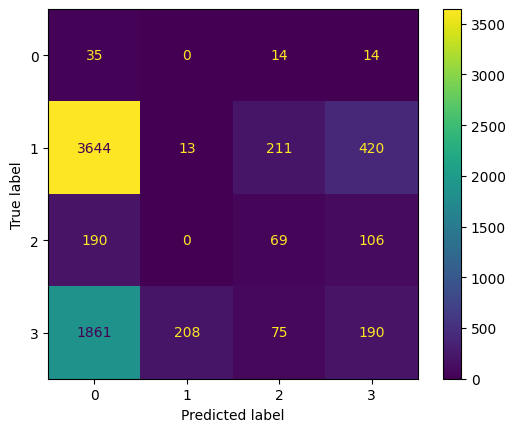

In [46]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labelEncoder = LabelEncoder()

y_true = labelEncoder.fit_transform(data["status_type"])

cm = confusion_matrix(y_true, poging2_kmeans.labels_)

ConfusionMatrixDisplay(cm).plot()
print(labelEncoder.classes_)